# Phase 1 — Data Preparation & Exploratory Data Analysis
## NLP Pipeline · Movie Review Sentiment Analysis

---

### Notebook Sections

| # | Section | Description |
|---|---------|-------------|
| 0 | Environment Setup | Imports, NLTK downloads, global plot theme |
| 1 | Data Loading | Read JSON → DataFrame, snapshot raw state |
| 2 | Data Cleaning | Drop nulls, deduplicate, cast dtypes |
| 3 | Target Engineering | Map ratings → Negative / Neutral / Positive |
| 4 | Text Preprocessing | Lowercase, remove HTML/URLs/punct, strip stopwords |
| 5 | Feature Extraction | Compute `review_length` (word count) |
| 6 | Dataset Overview | Before/After cleaning comparison report |
| 7a | EDA — Sentiment Distribution | Bar chart with % labels |
| 7b | EDA — Review Length | KDE + Boxplot per sentiment class |
| 7c | EDA — Word Clouds | Three side-by-side word clouds |
| 8 | Export | Save cleaned CSV for Phase 2 handoff |

---
## Section 0 — Environment Setup

In [3]:
# ── Standard library ─────────────────────────────────────────────────────────
import re
import json
import warnings

# ── Data manipulation ────────────────────────────────────────────────────────
import pandas as pd
import numpy as np

# ── Visualisation ────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from wordcloud import WordCloud

# ── NLP ──────────────────────────────────────────────────────────────────────
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# ── Suppress minor warnings that clutter notebook output ─────────────────────
warnings.filterwarnings('ignore')

# ── Download required NLTK assets (runs once; cached locally afterward) ──────
for resource in ['stopwords', 'punkt', 'punkt_tab']:
    nltk.download(resource, quiet=True)

# ── Global plot aesthetics ────────────────────────────────────────────────────
# Using the 'whitegrid' Seaborn theme throughout for a clean, academic look.
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.15)
plt.rcParams.update({
    'figure.dpi'       : 130,
    'axes.titlesize'   : 14,
    'axes.titleweight' : 'bold',
    'axes.labelsize'   : 12,
    'xtick.labelsize'  : 10,
    'ytick.labelsize'  : 10,
})

# ── Reproducibility seed ──────────────────────────────────────────────────────
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print('  Environment ready.')

  Environment ready.


---
## Section 1 — Data Loading & Initial Inspection

> We use `json.load()` instead of `pd.read_json()` to retain explicit control over encoding. A **pre-cleaning snapshot** is saved so we can produce a before/after comparison in Section 6.

In [4]:
def load_json_dataset(filepath: str) -> pd.DataFrame:
    """
    Load a JSON file that contains a list of review dictionaries.

    Parameters
    ----------
    filepath : str
        Relative or absolute path to the JSON file.

    Returns
    -------
    pd.DataFrame
        Raw DataFrame with one row per review.
    """
    with open(filepath, 'r', encoding='utf-8') as fh:
        raw_data = json.load(fh)
    return pd.DataFrame(raw_data)


# ── Load the raw dataset ──────────────────────────────────────────────────────
RAW_PATH = 'sample.json'          # ← update path if your file lives elsewhere
df_raw   = load_json_dataset(RAW_PATH)

# ── Snapshot BEFORE any cleaning ─────────────────────────────────────────────
# Save key metrics now for the before/after comparison in Section 6.
shape_before = df_raw.shape
nulls_before = df_raw.isnull().sum()
head_before  = df_raw.head(3)

print(f'Raw dataset loaded: {shape_before[0]:,} rows × {shape_before[1]} columns')
print(f'\nColumn names:\n  {list(df_raw.columns)}')

Raw dataset loaded: 100,000 rows × 9 columns

Column names:
  ['review_id', 'reviewer', 'movie', 'rating', 'review_summary', 'review_date', 'spoiler_tag', 'review_detail', 'helpful']


In [5]:
# Quick visual scan of the first few records
df_raw.head(3)

,review_id,reviewer,movie,rating,review_summary,review_date,spoiler_tag,review_detail,helpful
0,rw1133942,OriginalMovieBuff21,Kill Bill: Vol. 2 (2004),8,Good follow up that answers all the questions,24 July 2005,0,"After seeing Tarantino's Kill Bill Vol: 1, I g...","[0, 1]"
1,rw1133943,sentra14,Journey to the Unknown (1968– ),None,Excellent series,24 July 2005,0,"I have the entire series on video, taped mostl...","[11, 11]"
2,rw1133946,GreenwheelFan2002,The Island (2005),9,"Not just about action, but about survival...",24 July 2005,0,Once again the critics prove themselves as mor...,"[2, 5]"


In [6]:
# dtypes and memory usage
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   review_id       100000 non-null  object
 1   reviewer        100000 non-null  object
 2   movie           100000 non-null  object
 3   rating          87908 non-null   object
 4   review_summary  100000 non-null  object
 5   review_date     100000 non-null  object
 6   spoiler_tag     100000 non-null  int64 
 7   review_detail   100000 non-null  object
 8   helpful         100000 non-null  object
dtypes: int64(1), object(8)
memory usage: 6.9+ MB


In [7]:
print('Null counts (raw):')
print(df_raw.isnull().sum().to_string())

Null counts (raw):
review_id             0
reviewer              0
movie                 0
rating            12092
review_summary        0
review_date           0
spoiler_tag           0
review_detail         0
helpful               0


---
## Section 2 — Data Cleaning

| Step | Action | Reason |
|------|--------|--------|
| 1 | Drop duplicate `review_id` | One record per review |
| 2 | Drop null `rating` | Cannot label without a score |
| 3 | Drop null/empty `review_detail` | No text = no signal |
| 4 | Cast `rating` → `int` | Enables numeric bucketing |
| 5 | Reset index | Clean 0…N-1 index after drops |

In [8]:
def clean_dataset(df: pd.DataFrame) -> pd.DataFrame:
    """
    Apply foundational cleaning steps to the raw reviews DataFrame.

    Parameters
    ----------
    df : pd.DataFrame
        Raw DataFrame straight from load_json_dataset().

    Returns
    -------
    pd.DataFrame
        Cleaned copy (original is NOT mutated).
    """
    df = df.copy()

    # ── Step 1: Remove exact duplicate reviews ────────────────────────────────
    before_dedup = len(df)
    df.drop_duplicates(subset='review_id', inplace=True)
    print(f'  Step 1 — Removed {before_dedup - len(df):,} duplicate review_id rows.')

    # ── Step 2: Drop rows with a missing rating ───────────────────────────────
    # `rating` can be None/NaN because some IMDB reviews are posted without
    # a star score attached.
    before_rating = len(df)
    df.dropna(subset=['rating'], inplace=True)
    print(f'  Step 2 — Removed {before_rating - len(df):,} rows with null `rating`.')

    # ── Step 3: Drop rows with a missing or blank review body ─────────────────
    # Replace empty strings with NaN first so dropna() catches them.
    df['review_detail'].replace('', np.nan, inplace=True)
    before_detail = len(df)
    df.dropna(subset=['review_detail'], inplace=True)
    print(f'  Step 3 — Removed {before_detail - len(df):,} rows with null/empty `review_detail`.')

    # ── Step 4: Cast rating to integer ────────────────────────────────────────
    # Ratings arrive as strings ("8") or floats ("8.0"); cast via float first
    # to handle both safely.
    df['rating'] = df['rating'].astype(float).astype(int)
    print(f'  Step 4 — Converted `rating` dtype → int '
          f'(range: {df["rating"].min()}–{df["rating"].max()})')

    # ── Step 5: Reset index ───────────────────────────────────────────────────
    df.reset_index(drop=True, inplace=True)

    return df


print('Cleaning dataset …\n')
df_clean = clean_dataset(df_raw)
print(f'\n  Cleaning complete: {shape_before[0]:,} → {len(df_clean):,} rows retained.')

Cleaning dataset …

  Step 1 — Removed 2 duplicate review_id rows.
  Step 2 — Removed 12,092 rows with null `rating`.
  Step 3 — Removed 0 rows with null/empty `review_detail`.
  Step 4 — Converted `rating` dtype → int (range: 1–10)

  Cleaning complete: 100,000 → 87,906 rows retained.


---
## Section 3 — Target Engineering (Sentiment Labels)

Labels are assigned using `pd.cut()` with the following mapping:

| Rating | Sentiment |
|--------|-----------|
| 1 – 4  | Negative  |
| 5 – 6  | Neutral   |
| 7 – 10 | Positive  |

`pd.cut()` creates **half-open intervals** `(0,4]`, `(4,6]`, `(6,10]` — the right edge is included (`right=True`).

In [9]:
# ── Sentiment bin definition (matches assignment brief exactly) ───────────────
SENTIMENT_BINS   = [0, 4, 6, 10]               # breakpoints
SENTIMENT_LABELS = ['Negative', 'Neutral', 'Positive']


def assign_sentiment(df: pd.DataFrame) -> pd.DataFrame:
    """
    Append a `sentiment_label` column derived from `rating`.

    Parameters
    ----------
    df : pd.DataFrame
        Cleaned DataFrame with an integer `rating` column.

    Returns
    -------
    pd.DataFrame
        DataFrame with new `sentiment_label` (ordered Categorical) column.
    """
    df = df.copy()

    df['sentiment_label'] = pd.cut(
        df['rating'],
        bins   = SENTIMENT_BINS,
        labels = SENTIMENT_LABELS,
        right  = True            # intervals: (0,4], (4,6], (6,10]
    )

    # Enforce logical display order on the categorical
    # (ensures consistent ordering in all downstream plots)
    df['sentiment_label'] = pd.Categorical(
        df['sentiment_label'],
        categories = SENTIMENT_LABELS,
        ordered    = True
    )

    return df


df_clean = assign_sentiment(df_clean)

print(' Sentiment label distribution:')
print(df_clean['sentiment_label'].value_counts().to_string())

 Sentiment label distribution:
sentiment_label
Positive    57901
Negative    18235
Neutral     11770


In [10]:
# Verify the mapping is correct: show rating range per label
df_clean.groupby('sentiment_label', observed=True)['rating'].agg(['min', 'max', 'count'])

,min,max,count
sentiment_label,,,
Negative,1,4,18235
Neutral,5,6,11770
Positive,7,10,57901


---
## Section 4 — Text Preprocessing

A standard NLP cleaning pipeline applied to `review_detail` → stored in `cleaned_text`.

**Pipeline order matters:**
1. **Lowercase** — normalise casing before regex matching
2. **Strip HTML tags** — `<br/>` → space before punctuation removal
3. **Remove URLs** — links carry no sentiment signal
4. **Remove punctuation** — keep only `a-z` and whitespace
5. **Collapse whitespace** — normalise multiple spaces/newlines
6. **Remove stopwords** — drop high-frequency, low-signal words
7. **Rejoin** — reassemble tokens into a single clean string

> Regex patterns are **compiled once at module level** — reusing compiled automata is significantly faster than calling `re.sub()` with a string pattern on every row.

In [11]:
# ── Load English stopwords once (not inside the loop) ────────────────────────
STOP_WORDS = set(stopwords.words('english'))

# ── Compiled regex patterns ───────────────────────────────────────────────────
URL_PATTERN    = re.compile(r'https?://\S+|www\.\S+')   # http/https & www
HTML_PATTERN   = re.compile(r'<.*?>')                    # HTML tags e.g. <br/>
PUNCT_PATTERN  = re.compile(r'[^a-z\s]')                # keep only a-z + spaces
SPACES_PATTERN = re.compile(r'\s+')                     # collapse whitespace


def preprocess_text(text: str) -> str:
    """
    Apply a standard NLP cleaning pipeline to a single review string.

    Parameters
    ----------
    text : str
        Raw review body text.

    Returns
    -------
    str
        Cleaned, stopword-filtered text ready for feature extraction
        or vectorisation in later pipeline phases.
    """
    # Guard: return empty string for any non-string input
    if not isinstance(text, str):
        return ''

    text = text.lower()                             # 1. Lowercase
    text = HTML_PATTERN.sub(' ', text)              # 2. Strip HTML tags
    text = URL_PATTERN.sub(' ', text)               # 3. Strip URLs
    text = PUNCT_PATTERN.sub(' ', text)             # 4. Remove punctuation
    text = SPACES_PATTERN.sub(' ', text).strip()    # 5. Collapse whitespace

    # 6. Tokenise + stopword removal in one pass
    tokens = [tok for tok in text.split()
               if tok not in STOP_WORDS and len(tok) > 1]

    return ' '.join(tokens)                         # 7. Rejoin


print('  Preprocessing review text … (may take a moment on large datasets)')
df_clean['cleaned_text'] = df_clean['review_detail'].apply(preprocess_text)
print('  Done.')

  Preprocessing review text … (may take a moment on large datasets)
  Done.


In [12]:
# ── Sanity check: compare a raw vs cleaned review side-by-side ───────────────
sample_idx = 0
print('RAW TEXT (first 300 chars):')
print(df_clean['review_detail'].iloc[sample_idx][:300])
print()
print('CLEANED TEXT (first 300 chars):')
print(df_clean['cleaned_text'].iloc[sample_idx][:300])

RAW TEXT (first 300 chars):
After seeing Tarantino's Kill Bill Vol: 1, I got to watch Vol. 2 the next day after seeing it. I liked the first one but didn't really know everything that was going on, but just knowing that she set off the kill 5 individuals who left her dead at her wedding. So I saw Kill Bill: Vol 2 and liked it 

CLEANED TEXT (first 300 chars):
seeing tarantino kill bill vol got watch vol next day seeing liked first one really know everything going knowing set kill individuals left dead wedding saw kill bill vol liked highly movie answered questions previous one much better story unrealistic much finally get see bill played david carradine


---
## Section 5 — Feature Extraction

`review_length` = number of whitespace-delimited tokens in `cleaned_text` (after stopword removal).  
This is a proxy for **review verbosity** and will serve as a baseline numeric feature in Phase 2.

In [13]:
def extract_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Derive numerical features from `cleaned_text`.

    Features added
    --------------
    review_length : int
        Token count in `cleaned_text` (stopwords already removed).

    Parameters
    ----------
    df : pd.DataFrame

    Returns
    -------
    pd.DataFrame
    """
    df = df.copy()
    df['review_length'] = df['cleaned_text'].apply(
        lambda t: len(t.split()) if t else 0
    )
    return df


df_clean = extract_features(df_clean)

print('  review_length descriptive statistics:')
df_clean['review_length'].describe().round(2)

  review_length descriptive statistics:


count    87906.00
mean       126.57
std         87.39
min          6.00
25%         69.00
50%         93.00
75%        150.00
max        683.00
Name: review_length, dtype: float64

---
## Section 6 — Dataset Overview (Before / After Cleaning)

In [14]:
DIVIDER = '=' * 65

def print_dataset_report(
    df_before_shape : tuple,
    df_before_nulls : pd.Series,
    df_before_head  : pd.DataFrame,
    df_after        : pd.DataFrame
) -> None:
    """
    Print a structured before/after cleaning report to stdout.

    Parameters
    ----------
    df_before_shape : tuple       (rows, cols) of the raw DataFrame.
    df_before_nulls : pd.Series   Null counts per column of the raw DataFrame.
    df_before_head  : pd.DataFrame  First few rows of the raw DataFrame.
    df_after        : pd.DataFrame  The fully cleaned and engineered DataFrame.
    """
    # ── BEFORE ────────────────────────────────────────────────────────────────
    print(f'\n{DIVIDER}')
    print('  DATASET REPORT — BEFORE CLEANING')
    print(DIVIDER)
    print(f'  Shape       : {df_before_shape[0]:,} rows × {df_before_shape[1]} columns')
    print('\n  Null counts (columns with nulls):')
    top_nulls = df_before_nulls[df_before_nulls > 0]
    if top_nulls.empty:
        print('    No null values found.')
    else:
        for col, cnt in top_nulls.items():
            pct = 100 * cnt / df_before_shape[0]
            print(f'    {col:<25} {cnt:>6,}  ({pct:.1f}%)')

    # ── AFTER ─────────────────────────────────────────────────────────────────
    print(f'\n{DIVIDER}')
    print('  DATASET REPORT — AFTER CLEANING & FEATURE ENGINEERING')
    print(DIVIDER)
    print(f'  Shape       : {len(df_after):,} rows × {len(df_after.columns)} columns')
    print(f'  Rows dropped: {df_before_shape[0] - len(df_after):,} '
          f'({100*(df_before_shape[0]-len(df_after))/df_before_shape[0]:.1f}%)')

    after_nulls = df_after.isnull().sum()
    print('\n  Remaining null counts:')
    if after_nulls.sum() == 0:
        print('      No null values remain.')
    else:
        print(after_nulls[after_nulls > 0].to_string())

    print('\n  Column dtypes:')
    print(df_after.dtypes.to_string())

    print('\n  New columns added:')
    for col in ['sentiment_label', 'cleaned_text', 'review_length']:
        print(f'    ✔  {col}')

    print(f'\n{DIVIDER}\n')


print_dataset_report(shape_before, nulls_before, head_before, df_clean)


  DATASET REPORT — BEFORE CLEANING
  Shape       : 100,000 rows × 9 columns

  Null counts (columns with nulls):
    rating                    12,092  (12.1%)

  DATASET REPORT — AFTER CLEANING & FEATURE ENGINEERING
  Shape       : 87,906 rows × 12 columns
  Rows dropped: 12,094 (12.1%)

  Remaining null counts:
      No null values remain.

  Column dtypes:
review_id            object
reviewer             object
movie                object
rating                int64
review_summary       object
review_date          object
spoiler_tag           int64
review_detail        object
helpful              object
sentiment_label    category
cleaned_text         object
review_length         int64

  New columns added:
    ✔  sentiment_label
    ✔  cleaned_text
    ✔  review_length




In [15]:
# Visual preview of the cleaned DataFrame (key columns)
display_cols = ['review_id', 'rating', 'sentiment_label', 'review_length', 'cleaned_text']
df_clean[display_cols].head(5)

,review_id,rating,sentiment_label,review_length,cleaned_text
0,rw1133942,8,Positive,74,seeing tarantino kill bill vol got watch vol n...
1,rw1133946,9,Positive,145,critics prove morons movie definitely best see...
2,rw1133948,3,Negative,58,film done many times already guy confess true ...
3,rw1133949,10,Positive,74,chris farley one favorite comedians forever mi...
4,rw1133950,10,Positive,122,love anime series complaint lasted one season ...


---
## Section 7a — EDA: Sentiment Class Distribution

**Why this matters:** Class imbalance directly affects model training in Phase 2. If one class dominates, we may need over/under-sampling or class-weight adjustments.

In [16]:
# ── Shared colour palette — consistent across ALL three EDA charts ────────────
# Colourblind-safe and visually distinct.
PALETTE = {
    'Negative' : '#E05C5C',   # muted red
    'Neutral'  : '#F5A623',   # warm amber
    'Positive' : '#4CAF82',   # balanced green
}
SENTIMENT_ORDER = ['Negative', 'Neutral', 'Positive']

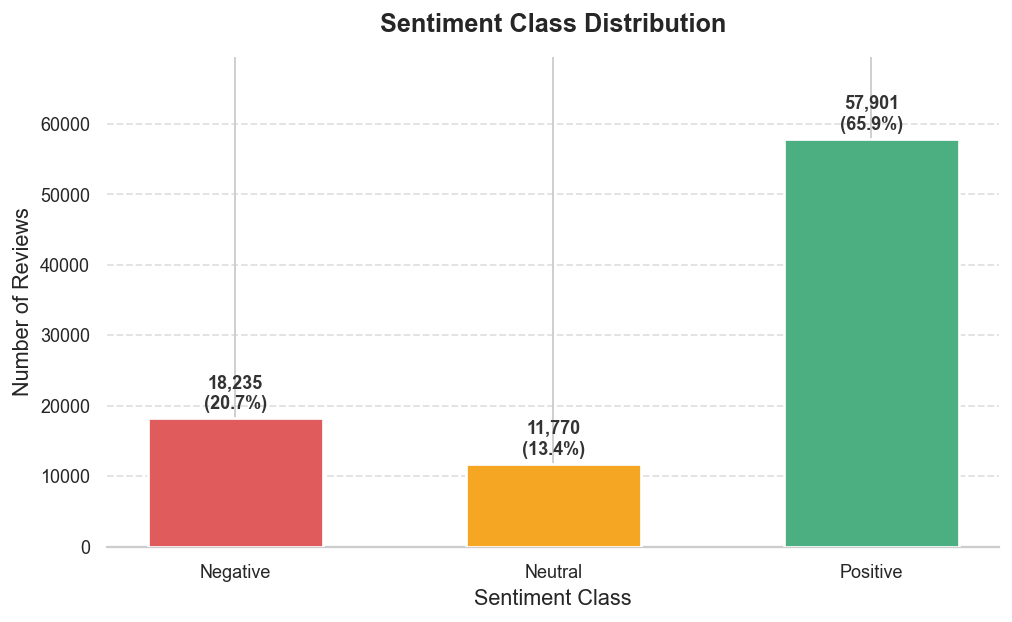

  Figure saved → 7a_sentiment_distribution.png


In [17]:
def plot_sentiment_distribution(df: pd.DataFrame) -> None:
    """
    Bar chart showing the count and percentage share of each sentiment class.

    Parameters
    ----------
    df : pd.DataFrame
        Cleaned DataFrame with a `sentiment_label` column.
    """
    counts = df['sentiment_label'].value_counts().reindex(SENTIMENT_ORDER)
    total  = counts.sum()
    pcts   = (counts / total * 100).round(1)

    fig, ax = plt.subplots(figsize=(8, 5))

    # Draw bars
    bars = ax.bar(
        SENTIMENT_ORDER,
        counts.values,
        color     = [PALETTE[s] for s in SENTIMENT_ORDER],
        edgecolor = 'white',
        linewidth = 1.5,
        width     = 0.55,
        zorder    = 3          # bars above the grid lines
    )

    # Annotate each bar with count + percentage
    for bar, count, pct in zip(bars, counts.values, pcts.values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,    # horizontal centre
            bar.get_height() + total * 0.008,      # slightly above bar top
            f'{count:,}\n({pct}%)',
            ha         = 'center',
            va         = 'bottom',
            fontsize   = 10,
            fontweight = 'bold',
            color      = '#333333',
        )

    # Styling
    ax.set_title('Sentiment Class Distribution', pad=14)
    ax.set_xlabel('Sentiment Class')
    ax.set_ylabel('Number of Reviews')
    ax.set_ylim(0, counts.max() * 1.2)     # headroom for labels
    ax.yaxis.grid(True, linestyle='--', alpha=0.6, zorder=0)
    ax.set_axisbelow(True)                  # grid behind bars
    sns.despine(ax=ax, left=True)

    plt.tight_layout()
    plt.savefig('7a_sentiment_distribution.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('  Figure saved → 7a_sentiment_distribution.png')


plot_sentiment_distribution(df_clean)

---
## Section 7b — EDA: Review Length by Sentiment

**Dual-panel figure:**
- **Top (KDE)** — reveals the full distribution shape, including bimodal patterns that a boxplot would hide.
- **Bottom (Boxplot)** — efficiently communicates median, IQR, and outliers.

> Extreme outliers are capped at the **99th percentile for display only** — the underlying `df_clean` data is never modified.

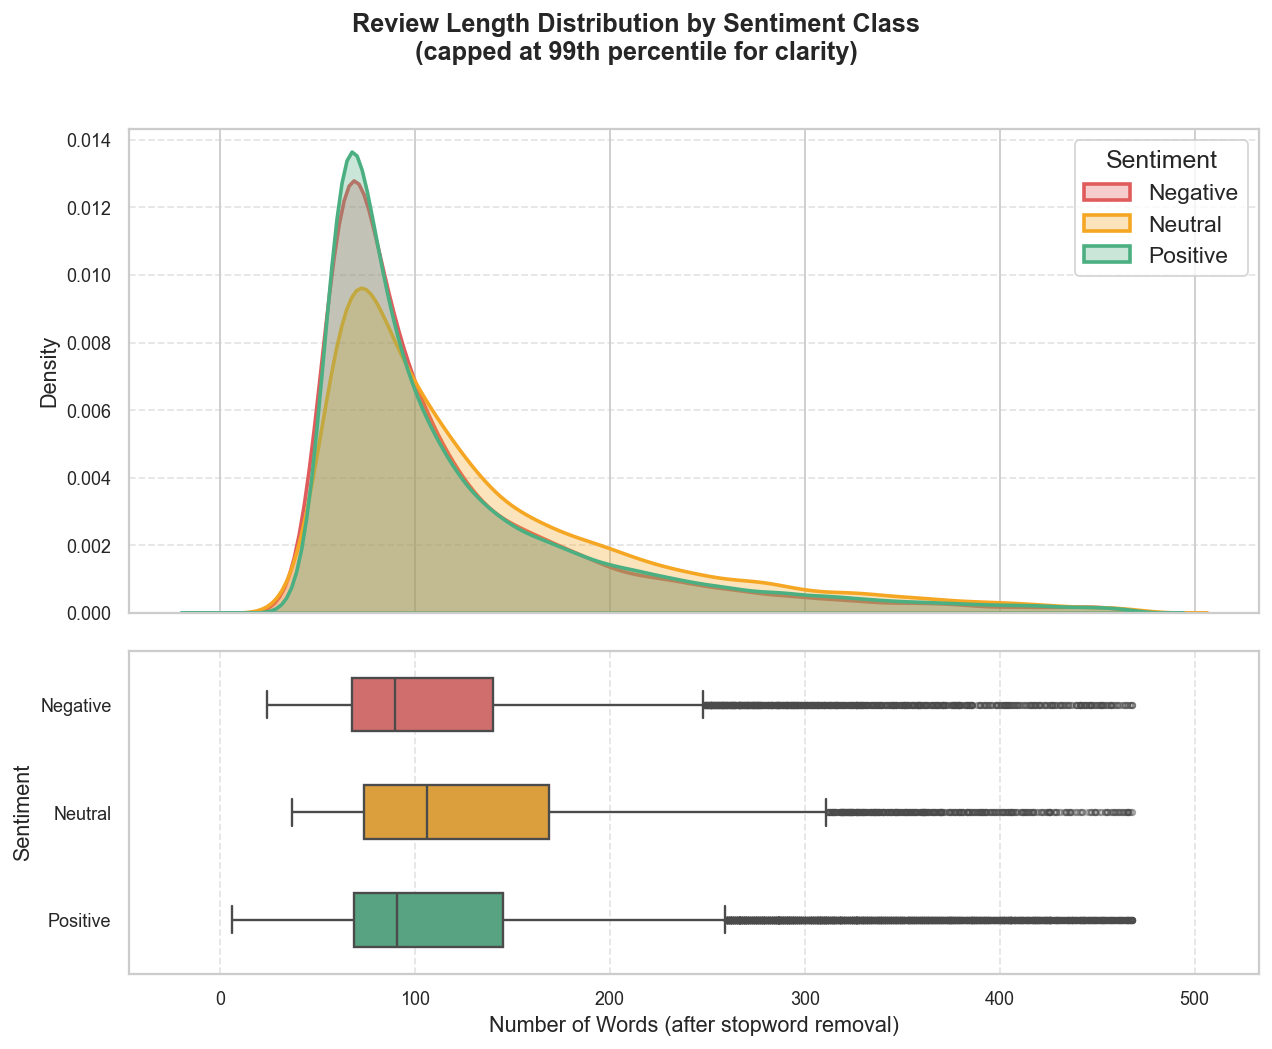

  Figure saved → 7b_review_length_by_sentiment.png


In [18]:
def plot_review_length_by_sentiment(df: pd.DataFrame) -> None:
    """
    Dual-panel (KDE + Boxplot) figure comparing review_length across
    sentiment classes.

    Parameters
    ----------
    df : pd.DataFrame
        Cleaned DataFrame with `sentiment_label` and `review_length` columns.
    """
    # Cap extreme outliers for visual clarity (display only — data unchanged)
    p99     = df['review_length'].quantile(0.99)
    df_plot = df[df['review_length'] <= p99].copy()

    fig, (ax_kde, ax_box) = plt.subplots(
        2, 1,
        figsize      = (10, 8),
        sharex       = True,      # shared x-axis: no duplicate tick labels
        gridspec_kw  = {'height_ratios': [3, 2]},
    )
    fig.suptitle(
        'Review Length Distribution by Sentiment Class\n'
        '(capped at 99th percentile for clarity)',
        fontsize=14, fontweight='bold', y=1.01
    )

    # ── KDE panel ─────────────────────────────────────────────────────────────
    for sentiment in SENTIMENT_ORDER:
        subset = df_plot.loc[
            df_plot['sentiment_label'] == sentiment, 'review_length'
        ]
        sns.kdeplot(
            subset,
            ax        = ax_kde,
            label     = sentiment,
            color     = PALETTE[sentiment],
            fill      = True,
            alpha     = 0.30,
            linewidth = 2.0,
        )

    ax_kde.set_ylabel('Density')
    ax_kde.legend(title='Sentiment', framealpha=0.8)
    ax_kde.yaxis.grid(True, linestyle='--', alpha=0.5)

    # ── Boxplot panel ──────────────────────────────────────────────────────────
    sns.boxplot(
        data       = df_plot,
        x          = 'review_length',
        y          = 'sentiment_label',
        order      = SENTIMENT_ORDER,
        palette    = PALETTE,
        orient     = 'h',
        width      = 0.5,
        linewidth  = 1.3,
        flierprops = dict(marker='o', markersize=3, alpha=0.3),
        ax         = ax_box,
    )

    ax_box.set_xlabel('Number of Words (after stopword removal)')
    ax_box.set_ylabel('Sentiment')
    ax_box.xaxis.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig('7b_review_length_by_sentiment.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('  Figure saved → 7b_review_length_by_sentiment.png')


plot_review_length_by_sentiment(df_clean)

---
## Section 7c — EDA: Word Clouds (Positive / Neutral / Negative)

Three side-by-side word clouds, each with a distinct colour map:

| Class | Colour Map | Reasoning |
|-------|-----------|----------|
| Positive | `YlGn` (yellow → green) | Growth, optimism |
| Neutral | `YlOrBr` (yellow → amber) | Warmth, balance |
| Negative | `OrRd` (orange → red) | Heat, dissatisfaction |

> `collocations=False` prevents a bigram like *"really good"* from inflating both its constituent unigrams.

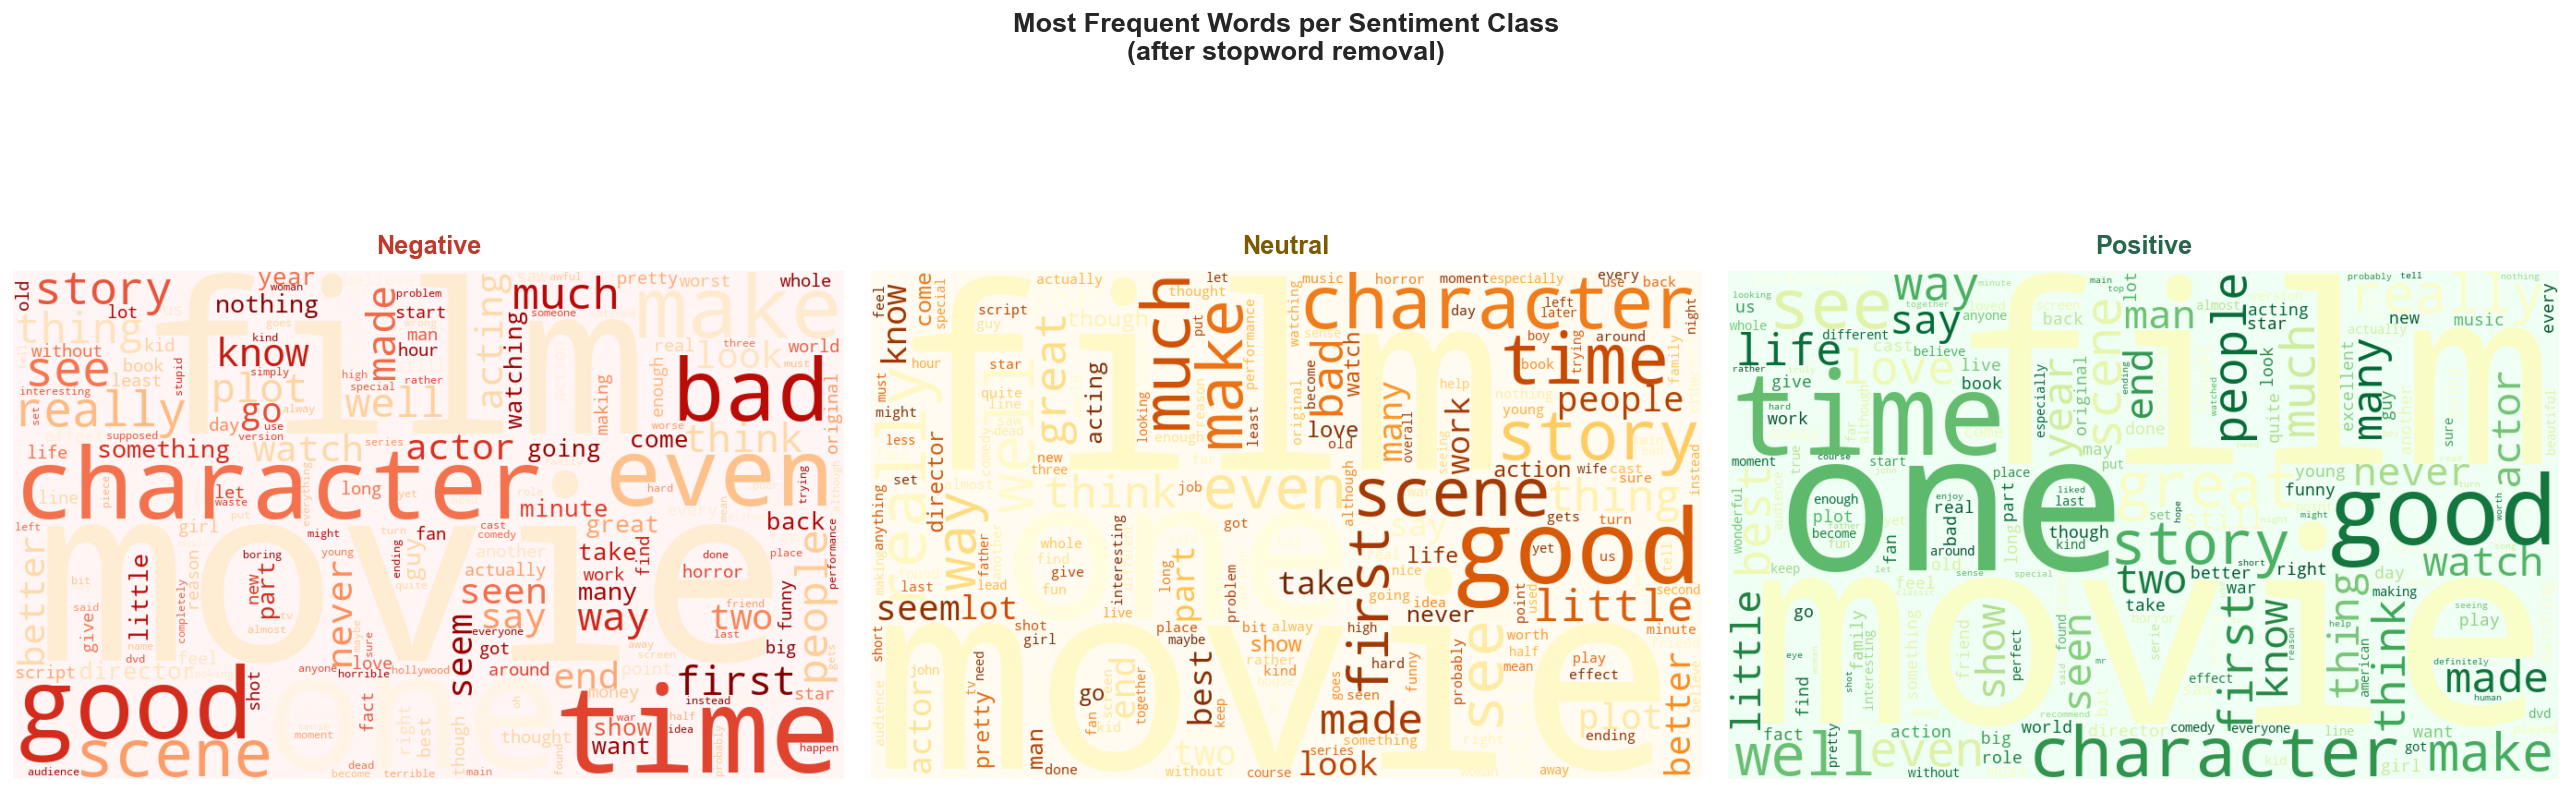

  Figure saved → 7c_wordclouds.png


In [19]:
def plot_wordclouds(df: pd.DataFrame) -> None:
    """
    Generate three distinct word clouds side-by-side, one per sentiment class.

    Parameters
    ----------
    df : pd.DataFrame
        Cleaned DataFrame with `sentiment_label` and `cleaned_text` columns.
    """
    # Per-class visual configuration
    wc_config = {
        'Positive': {
            'colormap'   : 'YlGn',
            'bg_color'   : '#F0FFF4',
            'title_color': '#276749',
        },
        'Neutral': {
            'colormap'   : 'YlOrBr',
            'bg_color'   : '#FFFBF0',
            'title_color': '#7D5A00',
        },
        'Negative': {
            'colormap'   : 'OrRd',
            'bg_color'   : '#FFF5F5',
            'title_color': '#C0392B',
        },
    }

    fig, axes = plt.subplots(1, 3, figsize=(20, 7), facecolor='white')
    fig.suptitle(
        'Most Frequent Words per Sentiment Class\n(after stopword removal)',
        fontsize=15, fontweight='bold', y=1.02
    )

    for ax, sentiment in zip(axes, SENTIMENT_ORDER):

        # Concatenate all cleaned reviews for this class
        corpus = ' '.join(
            df.loc[df['sentiment_label'] == sentiment, 'cleaned_text']
        )

        if not corpus.strip():
            # Edge case: no text available for this class
            ax.text(0.5, 0.5, 'No text available',
                    ha='center', va='center', transform=ax.transAxes)
            ax.set_title(sentiment)
            ax.axis('off')
            continue

        cfg = wc_config[sentiment]

        # Build the WordCloud
        wc = WordCloud(
            width             = 900,
            height            = 550,
            background_color  = cfg['bg_color'],
            colormap          = cfg['colormap'],
            max_words         = 200,
            collocations      = False,   # avoid double-counting bigrams
            prefer_horizontal = 0.85,
            min_font_size     = 8,
            random_state      = RANDOM_SEED,
        ).generate(corpus)

        # Render
        ax.imshow(wc, interpolation='bilinear')
        ax.axis('off')
        ax.set_title(
            sentiment,
            fontsize   = 14,
            fontweight = 'bold',
            color      = cfg['title_color'],
            pad        = 10,
        )

        # Subtle border for visual separation
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_edgecolor('#CCCCCC')
            spine.set_linewidth(1)

    plt.tight_layout()
    plt.savefig('7c_wordclouds.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('  Figure saved → 7c_wordclouds.png')


plot_wordclouds(df_clean)

---
## Section 8 — Export Cleaned Dataset (Phase 2 Handoff)

In [20]:
OUTPUT_PATH = 'movie_reviews_phase1_cleaned.csv'

df_clean.to_csv(OUTPUT_PATH, index=False)

print('=' * 65)
print('  PHASE 1 COMPLETE — OUTPUT SUMMARY')
print('=' * 65)
print(f'\n    Cleaned dataset saved → {OUTPUT_PATH}')
print(f'    Final shape          : {df_clean.shape[0]:,} rows × '
      f'{df_clean.shape[1]} columns')
print('\n  Key columns available for Phase 2:')
print('    • cleaned_text     — preprocessed review body (for TF-IDF / embeddings)')
print('    • sentiment_label  — 3-class target  (Negative / Neutral / Positive)')
print('    • review_length    — word count feature (baseline numeric feature)')
print('\n    Figures exported:')
for fig_name in [
    '7a_sentiment_distribution.png',
    '7b_review_length_by_sentiment.png',
    '7c_wordclouds.png',
]:
    print(f'    • {fig_name}')

  PHASE 1 COMPLETE — OUTPUT SUMMARY

    Cleaned dataset saved → movie_reviews_phase1_cleaned.csv
    Final shape          : 87,906 rows × 12 columns

  Key columns available for Phase 2:
    • cleaned_text     — preprocessed review body (for TF-IDF / embeddings)
    • sentiment_label  — 3-class target  (Negative / Neutral / Positive)
    • review_length    — word count feature (baseline numeric feature)

    Figures exported:
    • 7a_sentiment_distribution.png
    • 7b_review_length_by_sentiment.png
    • 7c_wordclouds.png


In [21]:
# Final preview of the exported DataFrame
df_clean[['review_id', 'rating', 'sentiment_label',
          'review_length', 'cleaned_text']].head(5)

,review_id,rating,sentiment_label,review_length,cleaned_text
0,rw1133942,8,Positive,74,seeing tarantino kill bill vol got watch vol n...
1,rw1133946,9,Positive,145,critics prove morons movie definitely best see...
2,rw1133948,3,Negative,58,film done many times already guy confess true ...
3,rw1133949,10,Positive,74,chris farley one favorite comedians forever mi...
4,rw1133950,10,Positive,122,love anime series complaint lasted one season ...
